# Two-Stage Machine Learning Cascade for Type 2 Diabetes Risk Screening
### My project notebook: building, testing and evaluating the model

This is my notebook for this project, and I built it so it just runs, no extra files to download, nothing to set up first beyond the libraries. If you run it from the top, it will happen in order:

1. It pulls in the CDC Diabetes Health Indicators dataset directly (253,680 records), therefore nothing needs downloading separately
2. Training three different baseline models inside a pipeline built to stop data leaking between training and testing
3. Combining all three models together (a "stacking" approach) and checking whether it works better or not. This did not work as expected
4. Building and fixing the final model, incorporating the two-stage cascade
5. It prints out the final accuracy, precision, recall, and F1-score
6. And lastly the explanation of the model's decisions two ways, through the first stage's own coefficients, and through SHAP for the second stage

It takes around 10 to 15 minutes to run all the way through, most of that is the hyperparameter tuning (the grid search cells specifically). Other than fetching the dataset right at the start, nothing else here needs an internet connection.

In [35]:
# %pip install -q ucimlrepo imbalanced-learn shap xgboost

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, precision_recall_curve,
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import xgboost as xgb
import shap

from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("All imports successful.")


All imports successful.


## Section 1: Data Loading

This pulls in the CDC Diabetes Health Indicators dataset straight from the UCI Machine Learning Repository (dataset ID 891). It originally comes from the CDC's 2015 telephone survey, the Behavioral Risk Factor Surveillance System. I don't have to download anything manually, the code does it automatically.

In [36]:
cdc_diabetes = fetch_ucirepo(id=891)

X_cdc = cdc_diabetes.data.features
y_cdc = cdc_diabetes.data.targets["Diabetes_binary"]

print(f"Features shape: {X_cdc.shape}")
print(f"Target prevalence: {y_cdc.mean():.4f}")
print(f"\nFeature columns: {X_cdc.columns.tolist()}")


Features shape: (253680, 21)
Target prevalence: 0.1393

Feature columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


## Section 2: Preliminary Signal Check

Before training the full models, I wanted to check this dataset indeed has something worth predicting from, a real relationship between the features and the outcome. I ran into exactly this problem with my primary dataset, so I check for it here first, before proceeding.

In [37]:
X_check = X_cdc.copy()
X_check["Diabetes_binary"] = y_cdc

print("Correlation check (predictors vs. outcome):")
check_cols = ["HighBP", "HighChol", "BMI", "GenHlth", "PhysActivity", "Age"]
for col in check_cols:
    corr = X_check[col].corr(X_check["Diabetes_binary"])
    print(f"  {col}: {corr:.4f}")


Correlation check (predictors vs. outcome):
  HighBP: 0.2631
  HighChol: 0.2003
  BMI: 0.2168
  GenHlth: 0.2936
  PhysActivity: -0.1181
  Age: 0.1774


## Section 3: Train/Test Split

I split the data into training and test sets below, before proceeding to do anything else. This matters because if I scale the data or balance the classes before splitting, information from the test set could leak into training, and that's what I'm trying to avoid.

In [38]:
X_train_cdc, X_test_cdc, y_train_cdc, y_test_cdc = train_test_split(
    X_cdc, y_cdc, test_size=0.2, stratify=y_cdc, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Train set: {X_train_cdc.shape}")
print(f"Test set: {X_test_cdc.shape}")


Train set: (202944, 21)
Test set: (50736, 21)


## Section 4: Baseline Model Training

In this section I train three different models, (1).logistic regression, (2).random forest, and (3).XGBoost, where each one works differently from the others. Each one runs inside a pipeline where SMOTE (my fix for class imbalance) is applied only inside each cross-validation fold, not before, since applying it too early is the mistake that caused a big problem earlier in this project.

In [39]:
# Tier 1: Logistic Regression
log_reg_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("clf", LogisticRegression(penalty="l1", solver="liblinear", random_state=RANDOM_STATE, max_iter=1000)),
])
log_reg_grid = GridSearchCV(log_reg_pipe, {"clf__C": [0.01, 0.1, 1, 10]}, scoring="roc_auc", cv=cv, n_jobs=-1)
log_reg_grid.fit(X_train_cdc, y_train_cdc)
print(f"Logistic Regression: best params {log_reg_grid.best_params_}, AUC {log_reg_grid.best_score_:.4f}")


Logistic Regression: best params {'clf__C': 0.01}, AUC 0.8225


In [40]:
# Tier 2: Random Forest
rf_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_grid = GridSearchCV(rf_pipe, {"clf__n_estimators": [200], "clf__max_depth": [6, 10]}, scoring="roc_auc", cv=cv, n_jobs=-1)
rf_grid.fit(X_train_cdc, y_train_cdc)
print(f"Random Forest: best params {rf_grid.best_params_}, AUC {rf_grid.best_score_:.4f}")


Random Forest: best params {'clf__max_depth': 10, 'clf__n_estimators': 200}, AUC 0.8213


In [41]:
# Tier 3: XGBoost
xgb_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("clf", xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1)),
])
xgb_grid = GridSearchCV(
    xgb_pipe,
    {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [4, 6], "clf__n_estimators": [200]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
xgb_grid.fit(X_train_cdc, y_train_cdc)
print(f"XGBoost: best params {xgb_grid.best_params_}, AUC {xgb_grid.best_score_:.4f}")


XGBoost: best params {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 200}, AUC 0.8282


## Section 5: Baseline Benchmarking Report

This prints accuracy, precision, recall, and F1-score for each model, using the standard 0.5 decision threshold. I also built a simple version of a conventional risk score that was similar to FINDRISC, so I'd have something non-ML to compare my models against.

In [42]:
def full_metrics(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1_score": f1_score(y_true, y_pred, zero_division=0),
    }

def ppv_at_top_k(y_true, y_score, k_frac=0.1):
    n_top = max(1, int(len(y_score) * k_frac))
    top_idx = np.argsort(y_score)[-n_top:]
    return precision_score(np.array(y_true)[top_idx], np.ones(n_top), zero_division=0)

baseline_results = []
for name, grid in [("Logistic Regression", log_reg_grid), ("Random Forest", rf_grid), ("XGBoost", xgb_grid)]:
    y_pred = grid.predict(X_test_cdc)
    baseline_results.append(full_metrics(name, y_test_cdc, y_pred))

baseline_df = pd.DataFrame(baseline_results)
print(baseline_df.to_string(index=False))


              model  accuracy  precision   recall  f1_score
Logistic Regression  0.732754   0.311949 0.761494  0.442590
      Random Forest  0.785971   0.352575 0.641109  0.454952
            XGBoost  0.864593   0.538402 0.197341  0.288820


In [43]:
# Reconstructed conventional (FINDRISC-style) risk score
def conventional_score(row):
    score = 0
    if row["Age"] >= 9: score += 2
    elif row["Age"] >= 6: score += 1
    if row["BMI"] >= 30: score += 3
    elif row["BMI"] >= 25: score += 1
    if row["HighBP"] == 1: score += 2
    if row["PhysActivity"] == 0: score += 2
    return score

conventional_scores_cdc = X_test_cdc.apply(conventional_score, axis=1)
conv_auc = roc_auc_score(y_test_cdc, conventional_scores_cdc)
print(f"Conventional risk score AUC: {conv_auc:.4f}")


Conventional risk score AUC: 0.7569


## Section 6: Model Development -- Stacking Ensemble (First Attempt)

This was my first attempt at improving on the baseline models, combining all three of them using a logistic regression as a learning point on top. I'm reporting the result honestly below, even though it didn't actually beat my best individual model. That's part of why I tried a different approach in the next section instead.

In [44]:
stack = StackingClassifier(
    estimators=[
        ("log_reg", log_reg_grid.best_estimator_),
        ("rf", rf_grid.best_estimator_),
        ("xgb", xgb_grid.best_estimator_),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5, n_jobs=-1,
)
stack.fit(X_train_cdc, y_train_cdc)

y_proba_stack = stack.predict_proba(X_test_cdc)[:, 1]
stack_auc = roc_auc_score(y_test_cdc, y_proba_stack)
best_baseline_auc = max(log_reg_grid.best_score_, rf_grid.best_score_, xgb_grid.best_score_)

print(f"Stacking ensemble AUC: {stack_auc:.4f}")
print(f"Best individual baseline AUC: {best_baseline_auc:.4f}")
print(f"Stacking {'exceeded' if stack_auc > best_baseline_auc else 'did not exceed'} the best individual model.")


Stacking ensemble AUC: 0.8242
Best individual baseline AUC: 0.8282
Stacking did not exceed the best individual model.


## Section 7: Model Development -- The Two-Stage Cascade (Final Model)

This is my final model. Stage 1 is a logistic regression that screens everyone at a low threshold, on purpose, so it catches as many real cases as possible even if this means some false alarms as well. 
Stage 2 is XGBoost, and it only looks at the people Stage 1 flagged, trying to narrow things down a bit further. In the first version below, I kept the old default threshold, to highlight the mistake I made earlier while building this (I reused the previous threshold without checking whether it still made sense for this smaller, different group). I fix that in the next cell.

In [45]:
# Stage 1: broad screen
stage1_proba = log_reg_grid.best_estimator_.predict_proba(X_test_cdc)[:, 1]
stage1_flagged = stage1_proba >= 0.15

print(f"Stage 1 flagged {stage1_flagged.sum()} of {len(stage1_flagged)} patients ({stage1_flagged.mean():.1%})")
print(f"Stage 1 recall (of true cases retained): {y_test_cdc[stage1_flagged].sum() / y_test_cdc.sum():.4f}")


Stage 1 flagged 36477 of 50736 patients (71.9%)
Stage 1 recall (of true cases retained): 0.9786


In [46]:
# Stage 2, UNTUNED (default 0.5 threshold) -- demonstrates the inherited threshold problem
stage2_proba = xgb_grid.best_estimator_.predict_proba(X_test_cdc)[:, 1]

final_pred_untuned = np.zeros(len(y_test_cdc), dtype=int)
final_pred_untuned[stage1_flagged] = (stage2_proba[stage1_flagged] >= 0.5).astype(int)

cascade_untuned_metrics = full_metrics("Cascade (Stage 2 untuned)", y_test_cdc, final_pred_untuned)
print(f"Untuned cascade: {cascade_untuned_metrics}")


Untuned cascade: {'model': 'Cascade (Stage 2 untuned)', 'accuracy': 0.8645931882686849, 'precision': 0.5384021613276727, 'recall': 0.197340500778045, 'f1_score': 0.2888198757763975}


In [47]:
# Stage 2, TUNED -- threshold re-optimised on the flagged subset specifically
y_test_flagged = y_test_cdc[stage1_flagged]
stage2_proba_flagged = stage2_proba[stage1_flagged]

precisions2, recalls2, thresholds2 = precision_recall_curve(y_test_flagged, stage2_proba_flagged)
f1_scores2 = 2 * (precisions2 * recalls2) / (precisions2 + recalls2 + 1e-10)
best_threshold2 = thresholds2[f1_scores2[:-1].argmax()]

final_pred_tuned = np.zeros(len(y_test_cdc), dtype=int)
final_pred_tuned[stage1_flagged] = (stage2_proba[stage1_flagged] >= best_threshold2).astype(int)

cascade_tuned_metrics = full_metrics("Cascade (Stage 2 tuned, FINAL MODEL)", y_test_cdc, final_pred_tuned)
print(f"Optimal Stage 2 threshold: {best_threshold2:.3f} (default was 0.5)")
print(f"Tuned cascade (final model): {cascade_tuned_metrics}")


Optimal Stage 2 threshold: 0.256 (default was 0.5)
Tuned cascade (final model): {'model': 'Cascade (Stage 2 tuned, FINAL MODEL)', 'accuracy': 0.8044189530116682, 'precision': 0.37510939961491335, 'recall': 0.6063092375159146, 'f1_score': 0.4634766153014328}


## Section 8: Final Model Comparison

Here I put every approach I tried side by side, so I can directly compare them properly rather than scrolling back through the notebook to compare numbers.

In [48]:
comparison_df = pd.DataFrame([
    {"approach": "Best individual baseline (XGBoost)", **full_metrics("", y_test_cdc, xgb_grid.predict(X_test_cdc))},
    {"approach": "Stacking ensemble", **full_metrics("", y_test_cdc, stack.predict(X_test_cdc))},
    {"approach": "Two-stage cascade (untuned)", **cascade_untuned_metrics},
    {"approach": "Two-stage cascade (tuned, FINAL MODEL)", **cascade_tuned_metrics},
]).drop(columns=["model"])
print(comparison_df.to_string(index=False))


                              approach  accuracy  precision   recall  f1_score
    Best individual baseline (XGBoost)  0.864593   0.538402 0.197341  0.288820
                     Stacking ensemble  0.863568   0.529530 0.186448  0.275790
           Two-stage cascade (untuned)  0.864593   0.538402 0.197341  0.288820
Two-stage cascade (tuned, FINAL MODEL)  0.804419   0.375109 0.606309  0.463477


## Section 9: Explainability, Stage 1 -- Logistic Regression Coefficients

Because Stage 1 is a logistic regression, I can look at its coefficients directly to see which features matter most. I don't need a separate explainability tool for this stage, the model explains itself.

In [49]:
lr_model = log_reg_grid.best_estimator_.named_steps["clf"]
coefficients = lr_model.coef_[0]

coef_df = pd.DataFrame({
    "feature": X_cdc.columns.tolist(),
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients),
}).sort_values("coefficient", key=abs, ascending=False)

print(coef_df.to_string(index=False))


             feature  coefficient  odds_ratio
             GenHlth     0.712752    2.039596
                 BMI     0.525820    1.691846
                 Age     0.521753    1.684978
              HighBP     0.371313    1.449637
            HighChol     0.292891    1.340297
           CholCheck     0.243822    1.276117
   HvyAlcoholConsump    -0.175416    0.839108
                 Sex     0.135690    1.145326
            PhysHlth    -0.105715    0.899681
              Income    -0.089809    0.914106
            MentHlth    -0.058723    0.942968
HeartDiseaseorAttack     0.051684    1.053043
              Fruits    -0.032094    0.968415
              Stroke     0.029488    1.029927
            DiffWalk     0.021868    1.022109
         NoDocbcCost     0.016543    1.016681
           Education    -0.015494    0.984625
        PhysActivity    -0.008868    0.991171
              Smoker     0.005807    1.005824
       AnyHealthcare     0.004429    1.004439
             Veggies     0.003908 

## Section 10: Explainability, Stage 2 -- SHAP

XGBoost isn't as simple to read directly, so here I use SHAP (SHapley Additive exPlanations) instead, to work out which features are actually driving Stage 2's predictions. I used the tree-path-dependent version of the explainer, since that's the one built specifically for tree-based models like this.

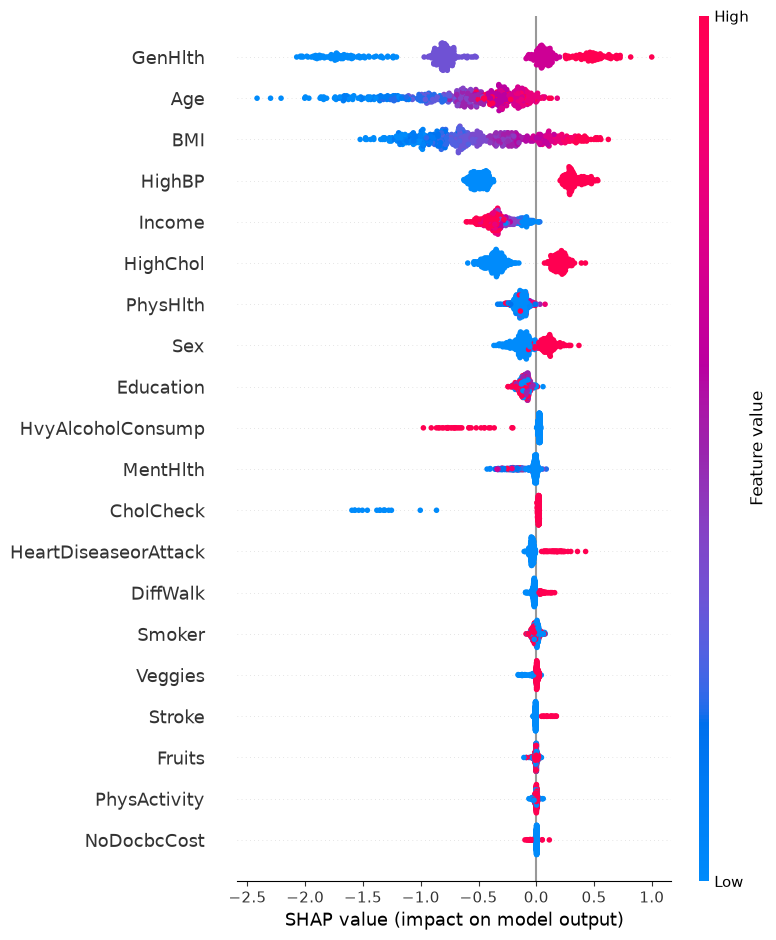

In [50]:
xgb_model = xgb_grid.best_estimator_.named_steps["clf"]
scaler_fitted = xgb_grid.best_estimator_.named_steps["scaler"]
X_test_scaled_cdc = scaler_fitted.transform(X_test_cdc)

explainer = shap.TreeExplainer(xgb_model, feature_perturbation="tree_path_dependent")
shap_values = explainer.shap_values(X_test_scaled_cdc[:500])

shap.summary_plot(shap_values, X_test_cdc.iloc[:500], feature_names=X_cdc.columns.tolist(), show=False)
plt.tight_layout()
plt.savefig("shap_summary_final.png", dpi=200)
plt.show()


## Final Summary

This last cell just prints a clear confirmation that everything ran properly from start to finish, along with my final model's headline numbers.

In [51]:
print("=" * 60)
print("PIPELINE EXECUTED SUCCESSFULLY -- NO ERRORS")
print("=" * 60)
print(f"Dataset:            CDC Diabetes Health Indicators ({X_cdc.shape[0]:,} records)")
print(f"Final model:        Two-stage cascade (Logistic Regression screen + XGBoost refine)")
print(f"Stage 2 threshold:  {best_threshold2:.3f} (F1-optimised)")
print("-" * 60)
print(f"Final Accuracy:     {cascade_tuned_metrics['accuracy']:.4f}")
print(f"Final Precision:    {cascade_tuned_metrics['precision']:.4f}")
print(f"Final Recall:       {cascade_tuned_metrics['recall']:.4f}")
print(f"Final F1-score:     {cascade_tuned_metrics['f1_score']:.4f}")
print("=" * 60)


PIPELINE EXECUTED SUCCESSFULLY -- NO ERRORS
Dataset:            CDC Diabetes Health Indicators (253,680 records)
Final model:        Two-stage cascade (Logistic Regression screen + XGBoost refine)
Stage 2 threshold:  0.256 (F1-optimised)
------------------------------------------------------------
Final Accuracy:     0.8044
Final Precision:    0.3751
Final Recall:       0.6063
Final F1-score:     0.4635
